In [1]:
from pathlib import Path
import shutil
import subprocess
import re
import os

# MESA installation
MESA_DIR = Path("/Users/mchau/mesa")

# Brown dwarf source directory
BROWN_DWARF_DIR = Path("/Users/mchau/mesa_tutorial/brown_dwarf")

# Where individual models will be stored
RUNS_DIR = BROWN_DWARF_DIR / "runs"
RUNS_DIR.mkdir(exist_ok=True)

print("MESA_DIR:", MESA_DIR)
print("Brown dwarf directory:", BROWN_DWARF_DIR)
print("Runs directory:", RUNS_DIR)

MESA_DIR: /Users/mchau/mesa
Brown dwarf directory: /Users/mchau/mesa_tutorial/brown_dwarf
Runs directory: /Users/mchau/mesa_tutorial/brown_dwarf/runs


In [2]:
# ============================
# BROWN DWARF INPUTS
# ============================

MASS_MJ = 10.0          # Brown dwarf mass in Jupiter masses
INITIAL_Z = 0.0142      # Metallicity
AGE_GYR = 5.0         # Evolutionary age in Gyr
INITIAL_RADIUS_RJ = 5.0 # Initial radius in Jupiter radii

print("Brown Dwarf Inputs")
print("------------------")
print(f"Mass:             {MASS_MJ:.1f} M_J")
print(f"Metallicity:      Z = {INITIAL_Z}")
print(f"Age:              {AGE_GYR:.2f} Gyr")
print(f"Initial radius:   {INITIAL_RADIUS_RJ:.1f} R_J")

Brown Dwarf Inputs
------------------
Mass:             10.0 M_J
Metallicity:      Z = 0.0142
Age:              5.00 Gyr
Initial radius:   5.0 R_J


In [5]:
# ============================
# UNIT CONVERSIONS
# ============================

M_JUP_G = 1.8986e30
R_JUP_CM = 6.9911e9

MASS_G = MASS_MJ * M_JUP_G
RADIUS_CM = INITIAL_RADIUS_RJ * R_JUP_CM

# MESA max_age is in years
MAX_AGE_YR = AGE_GYR * 1.0e9

# Convert Jupiter masses to solar masses
M_SUN_G = 1.9892e33
MASS_MSUN = MASS_G / M_SUN_G

print("MESA Inputs")
print("-----------")
print(f"Mass:       {MASS_G:.5e} g")
print(f"Mass:       {MASS_MSUN:.6f} M_sun")
print(f"Radius:     {RADIUS_CM:.5e} cm")
print(f"Age:        {MAX_AGE_YR:.5e} yr")

MESA Inputs
-----------
Mass:       1.89860e+31 g
Mass:       0.009545 M_sun
Radius:     3.49555e+10 cm
Age:        1.00000e+09 yr


In [6]:
# ============================
# CREATE RUN DIRECTORY
# ============================

Z_NAME = f"{INITIAL_Z:.4f}"
AGE_NAME = f"{AGE_GYR:g}"

RUN_NAME = (
    f"BD_{MASS_MJ:g}MJ_"
    f"Z{Z_NAME}_"
    f"AGE{AGE_NAME}Gyr"
)

RUN_DIR = RUNS_DIR / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Run name:")
print(RUN_NAME)

print("\nRun directory:")
print(RUN_DIR)

Run name:
BD_10MJ_Z0.0142_AGE1Gyr

Run directory:
/Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr


In [7]:
# ============================
# COPY BROWN DWARF FILES
# ============================

FILES_TO_COPY = [
    "inlist_make_brown_dwarf",
    "inlist_make_brown_dwarf_header",
    "mk",
    "rn",
    "rn1",
]

DIRECTORIES_TO_COPY = [
    "src",
    "make",
]

# Copy individual files
for filename in FILES_TO_COPY:
    source = BROWN_DWARF_DIR / filename
    destination = RUN_DIR / filename

    if source.exists():
        shutil.copy2(source, destination)
        print(f"Copied: {filename}")
    else:
        print(f"WARNING: {filename} not found")

# Copy required directories
for dirname in DIRECTORIES_TO_COPY:
    source = BROWN_DWARF_DIR / dirname
    destination = RUN_DIR / dirname

    if destination.exists():
        shutil.rmtree(destination)

    if source.exists():
        shutil.copytree(source, destination)
        print(f"Copied: {dirname}/")
    else:
        print(f"WARNING: {dirname}/ not found")

print("\nRun directory contents:")
for item in sorted(RUN_DIR.iterdir()):
    print(" ", item.name)

Copied: inlist_make_brown_dwarf
Copied: inlist_make_brown_dwarf_header
Copied: mk
Copied: rn
Copied: rn1
Copied: src/
Copied: make/

Run directory contents:
  inlist_make_brown_dwarf
  inlist_make_brown_dwarf_header
  make
  mk
  rn
  rn1
  src


In [8]:
# ============================
# CREATE MODEL INLIST
# ============================

inlist = f"""! inlist_make_brown_dwarf

&star_job

   show_log_description_at_start = .false.

   create_initial_model = .true.

   save_model_when_terminate = .true.
   save_model_filename = 'final.mod'

   required_termination_code_string = 'max_age'

   mass_in_gm_for_create_initial_model = {MASS_G:.6e}

   radius_in_cm_for_create_initial_model = {RADIUS_CM:.6e}

/ ! end of star_job namelist


&eos

/ ! end of eos namelist


&kap

   Zbase = {INITIAL_Z:.6f}

   kap_lowT_prefix = 'lowT_Freedman11'

/ ! end of kap namelist


&controls

   mlt_make_surface_no_mixing = .false.

   convergence_ignore_equL_residuals = .true.

   make_gradr_sticky_in_solver_iters = .true.

   use_gold2_tolerances = .true.

   max_model_number = 900

   initial_z = {INITIAL_Z:.6f}

   max_age = {MAX_AGE_YR:.6e}

   energy_eqn_option = 'dedt'

   warning_limit_for_max_residual = 1d99

   num_trace_history_values = 2

   trace_history_value_name(1) = 'rel_E_err'
   trace_history_value_name(2) = 'log_rel_run_E_err'

   max_resid_jump_limit = 1d15
   max_corr_jump_limit = 1d15

   photo_interval = 50
   profile_interval = 100
   history_interval = 10
   terminal_interval = 10

   write_header_frequency = 50

/ ! end of controls namelist


&pgstar

   Grid1_win_flag = .true.

   TRho_Profile_xmin = -8
   TRho_Profile_xmax = 4
   TRho_Profile_ymin = 2
   TRho_Profile_ymax = 6

/ ! end of pgstar namelist
"""

INLIST_PATH = RUN_DIR / "inlist_make_brown_dwarf"

INLIST_PATH.write_text(inlist)

print("Created:")
print(INLIST_PATH)

Created:
/Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr/inlist_make_brown_dwarf


In [9]:
# ============================
# CREATE MAIN INLIST
# ============================

header = """&star_job

   read_extra_star_job_inlist(2) = .true.
   extra_star_job_inlist_name(2) = 'inlist_make_brown_dwarf'

/ ! end of star_job namelist


&eos

   read_extra_eos_inlist(1) = .true.
   extra_eos_inlist_name(1) = 'inlist_make_brown_dwarf'

/ ! end of eos namelist


&kap

   read_extra_kap_inlist(1) = .true.
   extra_kap_inlist_name(1) = 'inlist_make_brown_dwarf'

/ ! end of kap namelist


&controls

   read_extra_controls_inlist(1) = .true.
   extra_controls_inlist_name(1) = 'inlist_make_brown_dwarf'

/ ! end of controls namelist


&pgstar

   read_extra_pgstar_inlist(1) = .true.
   extra_pgstar_inlist_name(1) = 'inlist_make_brown_dwarf'

/ ! end of pgstar namelist
"""

(RUN_DIR / "inlist").write_text(header)

print("Created main inlist.")

Created main inlist.


In [10]:
# ============================
# INITIALIZE MESA SDK + COMPILE
# ============================

env = os.environ.copy()

# MESA
env["MESA_DIR"] = str(MESA_DIR)

# MESA SDK
env["MESASDK_ROOT"] = "/Applications/mesasdk"

# Initialize the MESA SDK environment
sdk_init = Path(env["MESASDK_ROOT"]) / "bin" / "mesasdk_init.sh"

if not sdk_init.exists():
    raise FileNotFoundError(
        f"Could not find MESA SDK initialization script:\n{sdk_init}"
    )

# Source the SDK initialization script through bash
init_command = (
    f"source '{sdk_init}' && "
    f"cd '{RUN_DIR}' && "
    f"./mk"
)

print("Initializing MESA SDK and compiling...")
print("Run directory:", RUN_DIR)

result = subprocess.run(
    ["bash", "-lc", init_command],
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

if result.returncode == 0:
    print("\nMESA COMPILATION SUCCESSFUL")
else:
    print("\nMESA COMPILATION FAILED")
    print(result.stdout[-4000:])

Initializing MESA SDK and compiling...
Run directory: /Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr

MESA COMPILATION SUCCESSFUL


In [11]:
# ============================
# RUN MESA
# ============================

env = os.environ.copy()

env["MESA_DIR"] = str(MESA_DIR)
env["MESASDK_ROOT"] = "/Applications/mesasdk"

LOG_FILE = RUN_DIR / "mesa_run.log"

print("Starting MESA brown dwarf evolution...")
print("Run directory:", RUN_DIR)
print(f"Mass: {MASS_MJ:.1f} M_J")
print(f"Metallicity: Z = {INITIAL_Z}")
print(f"Age: {AGE_GYR:.2f} Gyr")

with open(LOG_FILE, "w") as log:
    result = subprocess.run(
        ["./star", "inlist"],
        cwd=RUN_DIR,
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT,
        text=True
    )

if result.returncode == 0:
    print("\nMESA RUN SUCCESSFUL")
    print("Full output saved to:")
    print(LOG_FILE)
else:
    print("\nMESA RUN FAILED")
    print("Check:")
    print(LOG_FILE)

Starting MESA brown dwarf evolution...
Run directory: /Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr
Mass: 10.0 M_J
Metallicity: Z = 0.0142
Age: 1.00 Gyr

MESA RUN SUCCESSFUL
Full output saved to:
/Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr/mesa_run.log


In [16]:
# ============================
# FIND MESA PROFILES
# ============================

LOGS_DIR = RUN_DIR / "LOGS"

profile_files = sorted(LOGS_DIR.glob("profile*.data"))

print("LOGS directory:")
print(LOGS_DIR)

print("\nProfiles found:")

for file in profile_files:
    print(" ", file.name)

print(f"\nTotal profiles: {len(profile_files)}")

LOGS directory:
/Users/mchau/mesa_tutorial/brown_dwarf/runs/BD_10MJ_Z0.0142_AGE1Gyr/LOGS

Profiles found:
  profile1.data
  profile2.data
  profile3.data

Total profiles: 3


In [15]:
# ============================
# READ LATEST PROFILE
# ============================

import sys

mesa_python = MESA_DIR / "utils" / "python"

if str(mesa_python) not in sys.path:
    sys.path.insert(0, str(mesa_python))

from mesa_reader import MesaData

profile_file = profile_files[-1]

profile = MesaData(str(profile_file))

print("Using:")
print(profile_file.name)

print(f"\nModel number: {profile.model_number}")
print(f"Age: {profile.star_age / 1e9:.3f} Gyr")
print(f"Mass: {profile.star_mass * 1047.3486:.2f} M_J")
print(f"Radius: {profile.photosphere_r * 9.735:.3f} R_J")

Using:
profile3.data

Model number: 203
Age: 1.000 Gyr
Mass: 10.00 M_J
Radius: 1.074 R_J


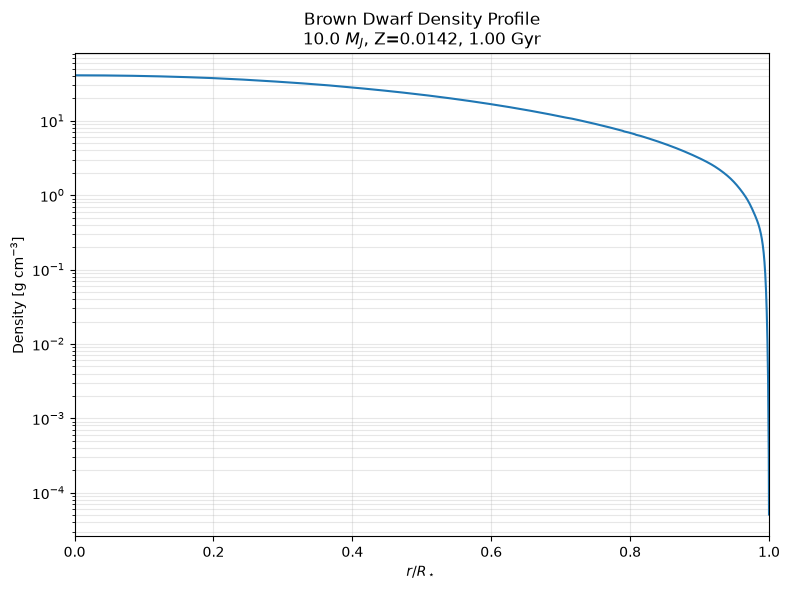

In [14]:
# ============================
# DENSITY PROFILE
# ============================

import matplotlib.pyplot as plt

logR = profile.logR
logRho = profile.logRho

# logR = log10(R / R_sun)
radius = 10**logR

# logRho = log10(rho / g cm^-3)
rho = 10**logRho

# Normalize radius
r_normalized = radius / radius.max()

plt.figure(figsize=(8, 6))

plt.plot(r_normalized, rho)

plt.yscale("log")

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"Density [g cm$^{-3}$]")

plt.title(
    f"Brown Dwarf Density Profile\n"
    f"{profile.star_mass * 1047.3486:.1f} $M_J$, "
    f"Z={profile.initial_z}, "
    f"{profile.star_age / 1e9:.2f} Gyr"
)

plt.xlim(0, 1)

plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()